# Task 3 - Monthly Spending Prediction (Regression, metric: NMAE)

CPE342 Karena Player Intelligence System

> **Rules followed:** models are trained from scratch (no pre-trained models, no AutoML); every statistic (blend weight, cut-off, number of trees) is chosen on **train** out-of-fold predictions only; the test set is used only for the final prediction.

The target is heavily skewed with many zeros, and MAE is minimised by the conditional **median**, so the models use an **L1 objective**. Two models are blended: a seed-bagged L1 LightGBM and a *quantile-mixture* model (classifier for P(pay) + quantile regressors on payers; the median of the mixture is read off the payer quantile (0.5 - p0) / (1 - p0)).

## 1. Import Libraries & Configuration

In [1]:
import os, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")

SEED = 42
QUICK = os.environ.get("QUICK") == "1"   # QUICK=1 -> small smoke test (results not meaningful)
ROOT = Path.cwd()                         # repo root, or the task3/ folder itself
OUT = ROOT / ("outputs_quick" if QUICK else "outputs")
(OUT / "models").mkdir(parents=True, exist_ok=True)
print("QUICK mode:", QUICK)

TASK, ID, TARGET = 3, "player_id", "spending_30d"
N_FOLDS = 3 if QUICK else 5
DATA = ROOT / "task3" if (ROOT / "task3" / "train.csv").exists() else ROOT   # run from repo root or from inside task3/

QUICK mode: False


In [2]:
# ---------- helper functions ----------
def nmae(y, p):
    # ASSUMPTION: NMAE = MAE / mean(y). Edit here if the task defines it differently
    # (e.g. divide by median(y) or by range).
    return np.mean(np.abs(y - p)) / np.mean(y)

def add_features(df):
    d = df.copy()
    d["spend_ratio"] = d["prev_month_spending"] / (d["historical_spending"] + 1)
    d["spend_per_day"] = d["historical_spending"] / (d["account_age_days"] + 1)
    d["txn_per_day"] = d["total_transactions"] / (d["account_age_days"] + 1)
    d["recency_x_freq"] = d["purchase_frequency"] / (d["days_since_last_purchase"] + 1)
    d["playtime_per_day"] = d["total_playtime_hours"] / (d["account_age_days"] + 1)
    d["no_history"] = ((d["historical_spending"].fillna(0) == 0) & (d["prev_month_spending"].fillna(0) == 0)).astype(int)
    d["log_prev"] = np.log1p(d["prev_month_spending"].clip(lower=0))
    d["log_hist"] = np.log1p(d["historical_spending"].clip(lower=0))
    d["season_cat"] = d["seasonal_spending_pattern"].astype("category")          # 0-11, uncorrelated with the target alone -> let trees use it as a category
    d["avg_txn_amt"] = d["historical_spending"] / (d["total_transactions"] + 1)
    d["prev_vs_avgmonth"] = d["prev_month_spending"] / (d["historical_spending"] / (d["account_age_days"] / 30 + 1) + 1)
    d["log_ratio"] = d["log_prev"] - d["log_hist"]
    return d.replace([np.inf, -np.inf], np.nan)

def make_l1(n_estimators=2000):
    return lgb.LGBMRegressor(objective="l1", n_estimators=n_estimators, learning_rate=0.03, num_leaves=63,
                             min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=SEED, verbose=-1)

def fit_l1(Xtr, ytr, Xva=None, yva=None, n_estimators=2000):
    m = make_l1(n_estimators)
    if Xva is not None:
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1", callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        m.fit(Xtr, ytr)
    return m

ALPHAS = [.05, .15, .3, .45, .6, .75, .9]
SEEDS = [SEED] if QUICK else [SEED, SEED + 1, SEED + 2]

def fit_qmix(Xtr, ytr):
    """Quantile mixture: classifier P(zero spend) + quantile regressors on payers.
    The conditional MEDIAN of (zero w.p. p0, payer distribution otherwise) is the payer quantile q = (0.5 - p0) / (1 - p0), or 0 if p0 >= 0.5."""
    pay = ytr > 1.0
    n = 100 if QUICK else 400
    clf = lgb.LGBMClassifier(n_estimators=n, learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1).fit(Xtr, pay)
    regs = [lgb.LGBMRegressor(objective="quantile", alpha=a, n_estimators=n, learning_rate=0.05, num_leaves=31, min_child_samples=40,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1).fit(Xtr[pay], ytr[pay])
            for a in ALPHAS]
    def predict(X):
        p0 = 1 - clf.predict_proba(X)[:, 1]
        Q = np.maximum.accumulate(np.clip(np.column_stack([r.predict(X) for r in regs]), 0, None), axis=1)
        q = np.clip((0.5 - p0) / (1 - p0 + 1e-9), 0, 1)
        xs = [0] + ALPHAS + [1]
        return np.array([np.interp(q[i], xs, [0] + list(Q[i]) + [Q[i, -1] * 1.3]) if q[i] > 0 else 0.0 for i in range(len(q))])
    return predict, clf, regs

def save_outputs(task, pred, model_obj, extra=None):
    df = pd.DataFrame({"id": [f"ANS{i + 1:05d}" for i in range(len(pred))], "pred": pred})
    for k, v in (extra or {}).items():
        df[k] = v
    df.to_csv(OUT / f"task{task}_pred.csv", index=False)
    joblib.dump(model_obj, OUT / "models" / f"task{task}_model.joblib")
    print(f"saved {len(df)} predictions -> {OUT / f'task{task}_pred.csv'}")
    print(f"saved model -> {OUT / 'models' / f'task{task}_model.joblib'}")

## 2. Load Data

In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
if QUICK:
    train = train.sample(20000, random_state=SEED).reset_index(drop=True)
print(f"Train shape: {train.shape}\nTest shape:  {test.shape}")
train.head()

Train shape: (104000, 34)
Test shape:  (25889, 33)


,player_id,friend_count,social_interactions,guild_membership,event_participation_rate,daily_login_streak,avg_session_length,sessions_per_week,total_playtime_hours,days_since_last_login,...,purchase_frequency,payment_methods_used,purchases_on_discount,discount_rate_used,seasonal_spending_pattern,owns_limited_edition,competitive_rank,tournament_participation,segment,spending_30d
0,P015192,178.0,96.0,0.0,35.268732,80.0,NaN,7.764709,780.113032,NaN,...,11.384819,NaN,9.0,0.360000,9.0,NaN,3.0,0.0,2.0,0.00
1,P111618,191.0,114.0,1.0,35.225308,67.0,130.116951,29.413024,403.615696,11.832143,...,11.810861,1.0,22.0,0.500000,1.0,0.0,8.0,0.0,1.0,0.00
2,P053928,221.0,137.0,0.0,37.170735,16.0,24.383195,26.243534,694.607894,14.069624,...,19.808857,2.0,12.0,0.545455,NaN,0.0,6.0,1.0,1.0,1837.52
3,P120339,235.0,61.0,0.0,55.991803,50.0,163.692017,7.678702,NaN,4.584786,...,2.111356,1.0,7.0,0.388889,3.0,0.0,6.0,0.0,2.0,0.00
4,P003004,24.0,86.0,1.0,11.119486,7.0,27.009295,2.459212,508.197429,14.110722,...,7.920881,2.0,18.0,0.391304,NaN,0.0,5.0,0.0,0.0,0.00


## 3. Exploratory Data Analysis (EDA)

EDA uses the **train** set only.

count    104000.00
mean      10497.04
std       30568.96
min           0.00
25%           0.00
50%          79.44
75%        2461.14
max      300000.00
share of zeros: 48.1%


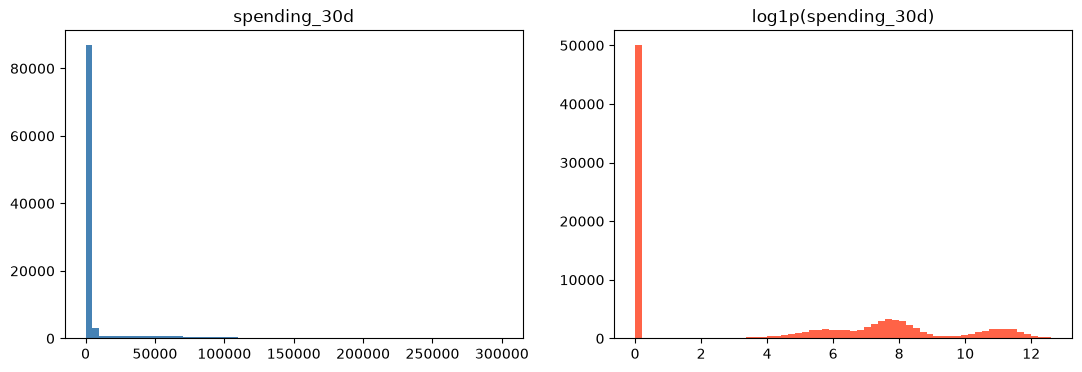

In [4]:
y_all = train[TARGET]
print(y_all.describe().round(2).to_string())
print(f"share of zeros: {(y_all == 0).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(y_all, bins=60, color="steelblue"); ax[0].set_title(TARGET)
ax[1].hist(np.log1p(y_all), bins=60, color="tomato"); ax[1].set_title(f"log1p({TARGET})")
plt.show()

max missing %: 6.0


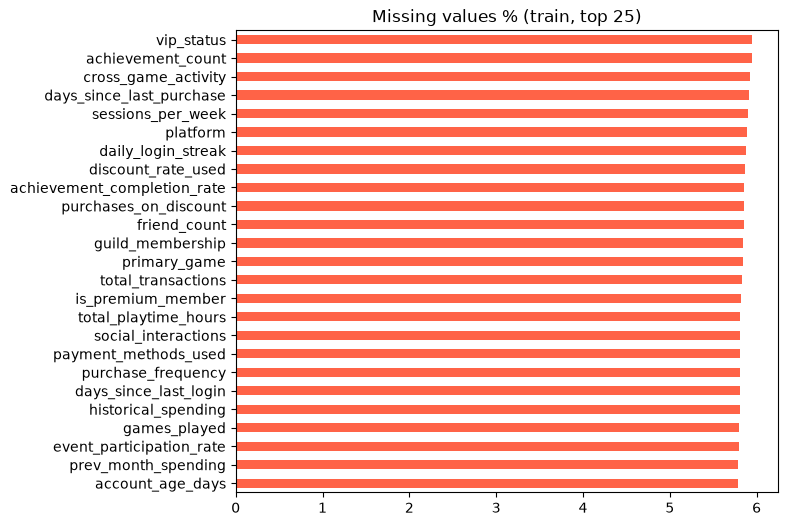

In [5]:
miss = (train.drop(columns=[TARGET]).isna().mean() * 100).sort_values(ascending=False)
print("max missing %:", round(miss.max(), 1))
miss[miss > 0].head(25).sort_values().plot(kind="barh", color="tomato", figsize=(7, 6), title="Missing values % (train, top 25)")
plt.show()

most relevant features: ['segment', 'prev_month_spending', 'historical_spending', 'event_participation_rate', 'avg_transaction_value', 'vip_status', 'is_premium_member', 'owns_limited_edition', 'total_transactions', 'purchases_on_discount']


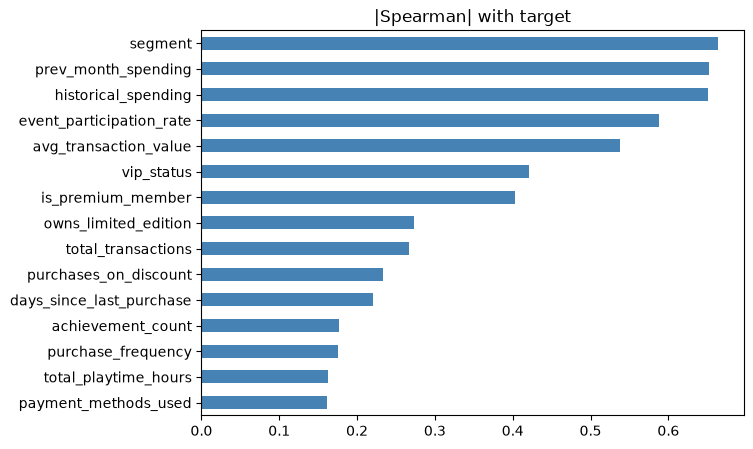

In [6]:
feats = train.drop(columns=[ID, TARGET]).select_dtypes("number")
top = feats.corrwith(train[TARGET], method="spearman").abs().fillna(0).sort_values(ascending=False).head(15)
print("most relevant features:", list(top.index[:10]))
top.sort_values().plot(kind="barh", figsize=(7, 5), color="steelblue", title="|Spearman| with target")
plt.show()

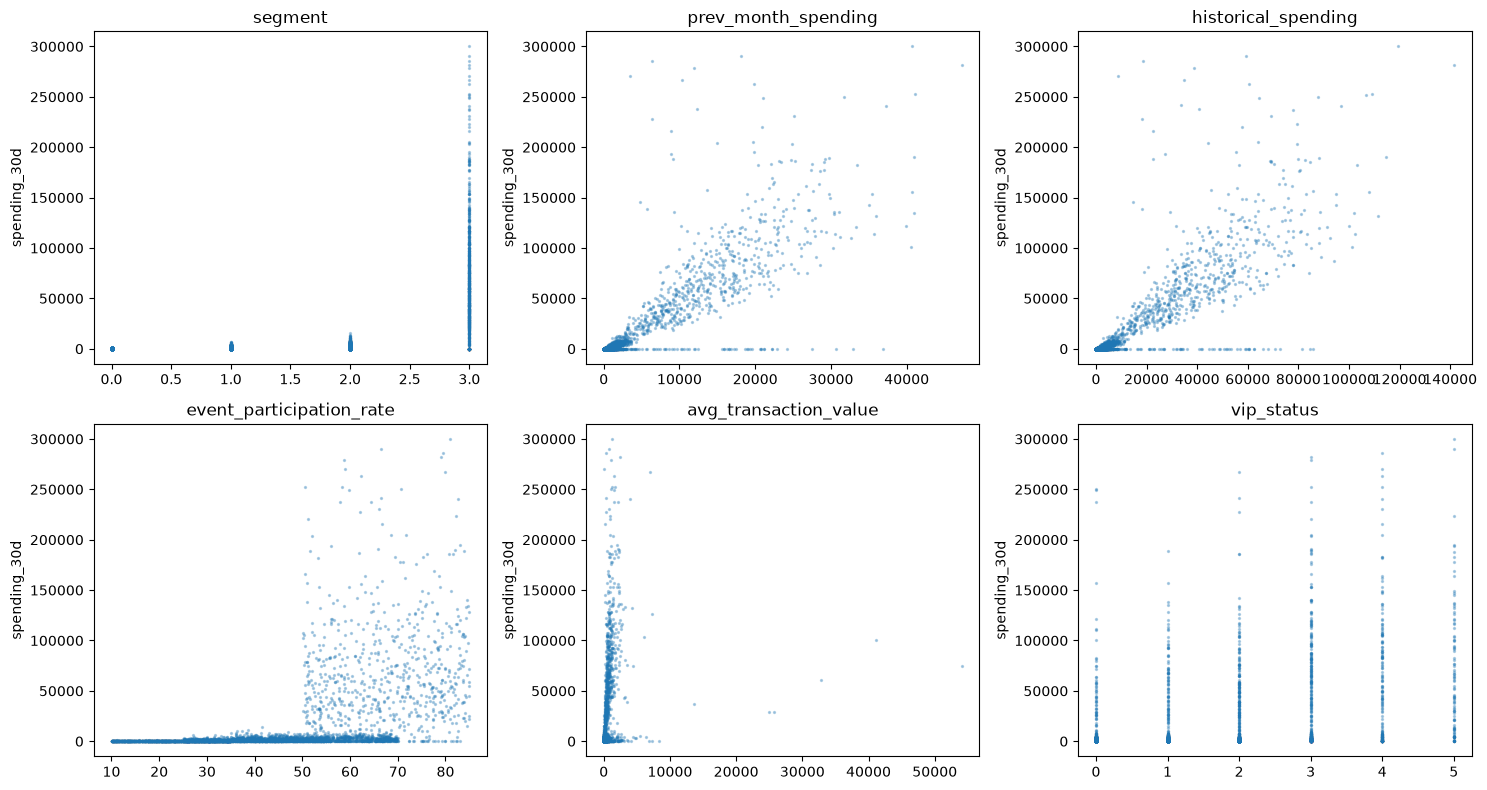

In [7]:
cols = list(top.index[:6])
s = train.sample(min(5000, len(train)), random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cols):
    ax.scatter(s[c], s[TARGET], s=2, alpha=0.3); ax.set_title(c); ax.set_ylabel(TARGET)
plt.tight_layout(); plt.show()

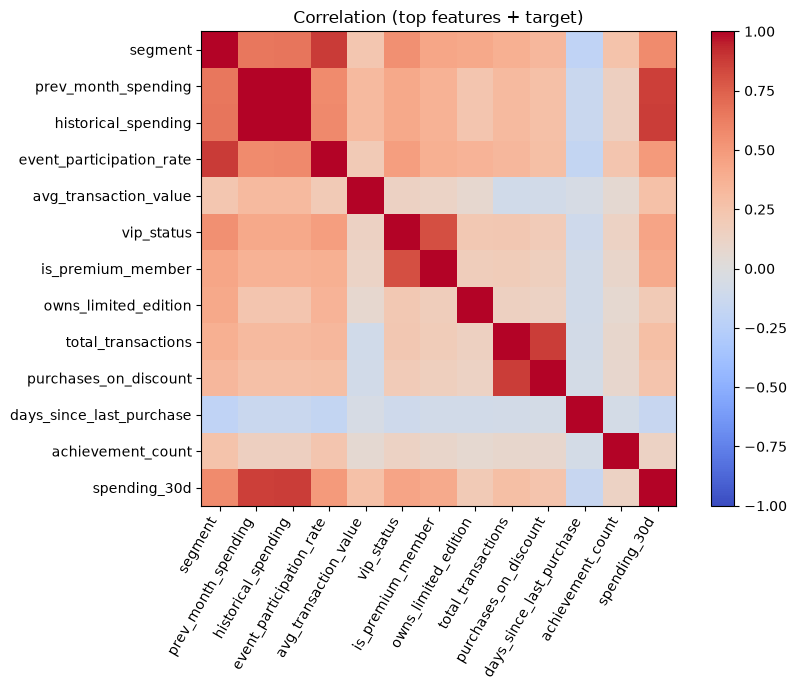

In [8]:
hm = feats[list(top.index[:12])].copy(); hm[TARGET] = train[TARGET]
c = hm.corr()
plt.figure(figsize=(9, 7)); plt.imshow(c, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(c)), c.columns, rotation=60, ha="right"); plt.yticks(range(len(c)), c.columns)
plt.title("Correlation (top features + target)"); plt.tight_layout(); plt.show()

## 4. Data Preprocessing

- the target is **not** clipped or transformed (MAE on the raw target is what is scored)
- engineered ratios: spending per day / transaction rate / playtime per day, previous month vs history, recency vs frequency, `no_history` flag, `log1p` of both spending columns
- missing values are left as NaN (LightGBM / HistGradientBoosting handle them natively); `inf` from ratios is turned into NaN

In [9]:
X_all = add_features(train.drop(columns=[ID, TARGET]))
y = train[TARGET].values
X_test = add_features(test.drop(columns=[ID]))[X_all.columns]
print(f"features: {X_all.shape[1]}")
print("baselines (NMAE):")
print("  median     :", round(nmae(y, np.full(len(y), np.median(y))), 4))
print("  prev_month :", round(nmae(y, train["prev_month_spending"].fillna(0).values), 4))

features: 44
baselines (NMAE):
  median     : 0.9999
  prev_month : 0.8344


## 5. Model Training & Validation

### 5.1 5-fold CV: seed-bagged L1 LightGBM vs quantile-mixture model (metric: NMAE, lower is better)
The blend weight are chosen on the out-of-fold predictions.

In [10]:
kf = KFold(N_FOLDS, shuffle=True, random_state=SEED)
oof_l1 = np.zeros(len(y))
oof_qm = np.zeros(len(y))
best_iters = []

for k, (tr, va) in enumerate(kf.split(X_all)):
    Xtr, Xva, ytr, yva = X_all.iloc[tr], X_all.iloc[va], y[tr], y[va]
    preds, its = [], []
    for sd in SEEDS:                                          # seed bagging of the L1 model
        m = make_l1(200 if QUICK else 2000).set_params(random_state=sd)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1", callbacks=[lgb.early_stopping(100, verbose=False)])
        preds.append(np.clip(m.predict(Xva), 0, None)); its.append(m.best_iteration_ or m.n_estimators)
    best_iters.append(int(np.mean(its)))
    oof_l1[va] = np.mean(preds, axis=0)
    oof_qm[va] = fit_qmix(Xtr, ytr)[0](Xva)
    print(f"fold {k + 1}/{N_FOLDS}: L1 (seed-bag) NMAE = {nmae(yva, oof_l1[va]):.4f} | quantile-mixture = {nmae(yva, oof_qm[va]):.4f}")

best_w, best_s = 1.0, nmae(y, oof_l1)
for w in np.linspace(0, 1, 11):
    s = nmae(y, w * oof_l1 + (1 - w) * oof_qm)
    if s < best_s:
        best_w, best_s = w, s
oof = np.clip(best_w * oof_l1 + (1 - best_w) * oof_qm, 0, 300000)

print("\n=== CV (out-of-fold) ===")
print("L1 seed-bag      :", round(nmae(y, oof_l1), 4))
print("Quantile mixture :", round(nmae(y, oof_qm), 4))
print(f"Blend            : {best_s:.4f} (weight L1={best_w:.1f})")


fold 1/5: L1 (seed-bag) NMAE = 0.2774 | quantile-mixture = 0.2788


fold 2/5: L1 (seed-bag) NMAE = 0.2761 | quantile-mixture = 0.2771


fold 3/5: L1 (seed-bag) NMAE = 0.2638 | quantile-mixture = 0.2637


fold 4/5: L1 (seed-bag) NMAE = 0.2732 | quantile-mixture = 0.2735


fold 5/5: L1 (seed-bag) NMAE = 0.2775 | quantile-mixture = 0.2788

=== CV (out-of-fold) ===
L1 seed-bag      : 0.2736
Quantile mixture : 0.2744
Blend            : 0.2722 (weight L1=0.5)


### 5.2 Error analysis (out-of-fold)

Share of total abs error by group:
grp
zero         0.309
low<=1k      0.015
mid<=20k     0.060
whale>20k    0.616
Name: ae, dtype: float64


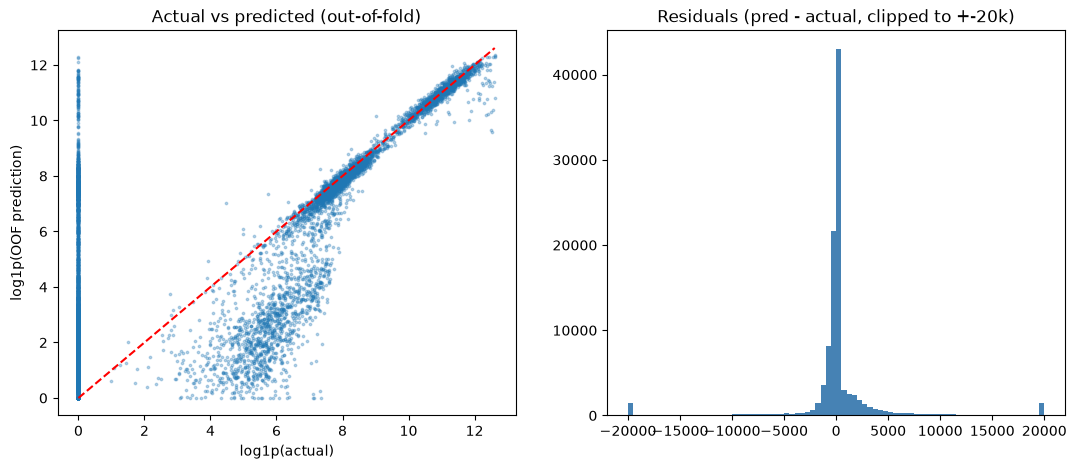

In [11]:
grp = pd.cut(y, [-1, 0, 1000, 20000, 1e9], labels=["zero", "low<=1k", "mid<=20k", "whale>20k"])
bd = pd.DataFrame({"grp": grp, "ae": np.abs(y - oof)}).groupby("grp", observed=True)["ae"]
print("Share of total abs error by group:")
print((bd.sum() / bd.sum().sum()).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
s = np.random.RandomState(SEED).choice(len(y), min(8000, len(y)), replace=False)
ax[0].scatter(np.log1p(y[s]), np.log1p(oof[s]), s=3, alpha=0.3)
lim = np.log1p(y.max()); ax[0].plot([0, lim], [0, lim], "r--")
ax[0].set_xlabel("log1p(actual)"); ax[0].set_ylabel("log1p(OOF prediction)"); ax[0].set_title("Actual vs predicted (out-of-fold)")
ax[1].hist(np.clip(oof - y, -20000, 20000), bins=80, color="steelblue"); ax[1].set_title("Residuals (pred - actual, clipped to +-20k)")
plt.show()

## 6. Predict on the Test Set & Save

test prediction: min 0.0 | mean 10359.7 | max 239105.8   (train target mean 10497.0, max 300000)


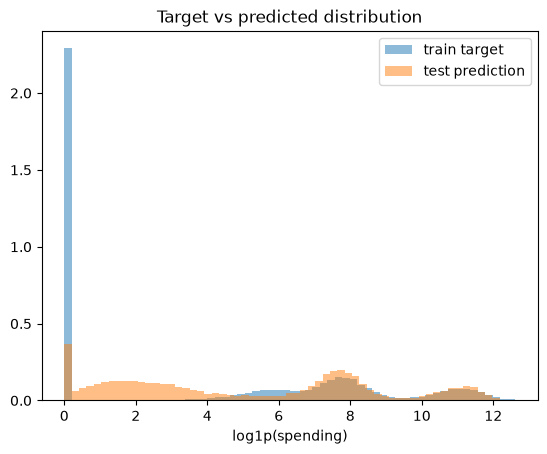

saved 25889 predictions -> C:\Users\ACER\OneDrive\Documents\GitHub\CPE342-Hackathon\task3\outputs\task3_pred.csv
saved model -> C:\Users\ACER\OneDrive\Documents\GitHub\CPE342-Hackathon\task3\outputs\models\task3_model.joblib


In [12]:
n_final = int(np.mean(best_iters) * 1.1)
final_l1 = []
for sd in SEEDS:
    final_l1.append(make_l1(n_final).set_params(random_state=sd).fit(X_all, y))
qm_final, qm_clf, qm_regs = fit_qmix(X_all, y)

p_l1 = np.clip(np.mean([m.predict(X_test) for m in final_l1], axis=0), 0, None)
p_qm = qm_final(X_test)
pred = np.clip(best_w * p_l1 + (1 - best_w) * p_qm, 0, 300000)

print(f"test prediction: min {pred.min():.1f} | mean {pred.mean():.1f} | max {pred.max():.1f}   (train target mean {y.mean():.1f}, max {y.max():.0f})")
plt.hist(np.log1p(y), bins=60, alpha=0.5, density=True, label="train target")
plt.hist(np.log1p(pred), bins=60, alpha=0.5, density=True, label="test prediction")
plt.xlabel("log1p(spending)"); plt.legend(); plt.title("Target vs predicted distribution"); plt.show()
save_outputs(TASK, pred, {"l1_models": final_l1, "qmix_clf": qm_clf, "qmix_regs": qm_regs, "alphas": ALPHAS,
                          "blend_weight_l1": best_w, "features": list(X_all.columns)})